In [1]:
import pandas as pd
import numpy as np

In [2]:
data_src = r"ai4omics-data-challenge-cancers-main"
X_train = pd.read_csv(f"{data_src}/T1_X_train.csv",sep=";",index_col=0)
y_train = pd.read_csv(f"{data_src}/T1_y_train.csv",sep=";",index_col=0)

print("X_train shape:",X_train.shape)
print("y_train shape:",y_train.shape)
 

X_train shape: (831, 5135)
y_train shape: (831, 1)


Section 1.1 – Descriptive statistics

In [71]:
print(y_train["target"].value_counts())

target
ADK    430
SQC    401
Name: count, dtype: int64


In [72]:
print("Average:")
print(y_train["target"].value_counts(normalize=True) * 100)

Average:
target
ADK    51.744886
SQC    48.255114
Name: proportion, dtype: float64


In [73]:
print("Missing value X_train",X_train.isna().sum().sum())
print("Missing value y_train",y_train.isna().sum().sum())

Missing value X_train 0
Missing value y_train 0


In [74]:
import matplotlib.pyplot as plt

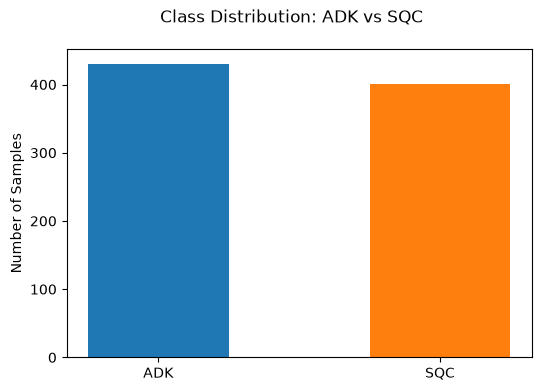

In [75]:
counts = y_train["target"].value_counts()
plt.figure(figsize=(6,4))
plt.bar(counts.index,counts.values,color=['#1f77b4', '#ff7f0e'],width=0.5)
plt.ylabel("Number of Samples")
plt.suptitle("Class Distribution: ADK vs SQC")
plt.show()

In [76]:
print(y_train.head(2))
y_train_num = (y_train["target"] == "SQC").astype(int)
print(y_train_num.head())

          target
id_sample       
SM3376       SQC
SM2702       ADK
id_sample
SM3376    1
SM2702    0
SM2880    0
SM3195    1
SM2932    0
Name: target, dtype: int64


In [77]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scale = scaler.fit_transform(X_train) 

In [78]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(C=0.1,max_iter=1000,random_state=42)

In [ ]:
from sklearn.model_selection import StratifiedKFold,cross_val_score
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scores = cross_val_score(model,x_train_scale,y_train_num,cv=cv,scoring="accuracy")
print("5 fold accuracy: ",scores)
print(f"Average Accucarcy: {scores.mean() * 100:.2f}%")

5 fold accuracy:  [0.94610778 0.94578313 0.96385542 0.92168675 0.98192771]
Average Accucarcy: 95.19%


In [86]:
from sklearn.model_selection import cross_validate
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
results = cross_validate(model,x_train_scale,y_train_num,cv=cv,scoring=scoring)

for metric in scoring:
 score = results[f"test_{metric}"]
 print(f"{metric.upper()}: {score.mean():.4f} (+/- {score.std():.4f})")

ACCURACY: 0.9519 (+/- 0.0201)
PRECISION: 0.9596 (+/- 0.0179)
RECALL: 0.9402 (+/- 0.0389)
F1: 0.9493 (+/- 0.0217)
ROC_AUC: 0.9847 (+/- 0.0063)


In [88]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve,auc

y_probs = cross_val_predict(model,x_train_scale,y_train_num,cv=cv,method="predict_log_proba")[:,1]
fpr,tpr,_ = roc_curve(y_train_num,y_probs)
roc_auc = auc(fpr,tpr)
print(f"Calculated ROC-AUC Score: {roc_auc:.4f}")

Calculated ROC-AUC Score: 0.9839


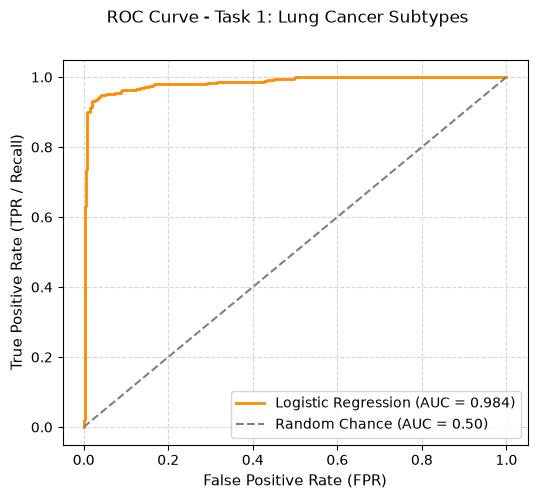

In [91]:
plt.figure(figsize=(6, 5))
# 1. Logistic Regression ROC curve (Orange line)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Logistic Regression (AUC = {roc_auc:.3f})')
# 2. Random chance baseline (Grey dotted line)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Chance (AUC = 0.50)')
# 3. Axis labels, title, and legend
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=11)
plt.suptitle('ROC Curve - Task 1: Lung Cancer Subtypes', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [92]:
# 1. Load test dataset
X_test = pd.read_csv(f"{data_src}/T1_X_test.csv", sep=';', index_col=0)

# 2. Standardize test features using training scaler parameters (transform only)
X_test_scaled = scaler.transform(X_test)

print("Test samples count:", X_test.shape[0])
print("Genes count:", X_test.shape[1])

Test samples count: 200
Genes count: 5135


In [94]:
 
model.fit(x_train_scale, y_train_num)
 
test_preds = model.predict(X_test_scaled)
 
test_labels = np.where(test_preds == 1, 'SQC', 'ADK')
 
print(pd.Series(test_labels).value_counts())
# Save predictions in required format
submission_t1 = pd.DataFrame({'id_sample': X_test.index, 'target': test_labels})
submission_t1.to_csv('T1_y_test.csv', sep=';', index=False)
print('T1_y_test.csv saved successfully!')


ADK    105
SQC     95
Name: count, dtype: int64
